<a href="https://colab.research.google.com/github/saludiosque/Proyecto-Final----Bioinformatica-2026/blob/main/Proyecto_Bioinformatica_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Procesamiento datos del paper

Carga y preprocesamiento de datos

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
path_tabla1 = '/content/drive/MyDrive/Proyecto_Bioinformatica/Tablas_de_Datos/Tabla_SNP.parquet'
path_tabla2 = '/content/drive/MyDrive/Proyecto_Bioinformatica/Tablas_de_Datos/Supplementary Tables.xlsx'

Tabla_SNP = pd.read_parquet(path_tabla1).set_index('rs#')
Tabla_Morf = pd.read_excel(path_tabla2, sheet_name=0, header=2, nrows=161).dropna(subset=['Subpopulation', 'fruitWeight (g)']).copy()
Tabla_Morf['Subpopulation'] = Tabla_Morf['Subpopulation'].astype(str).str.strip().str.upper()
Tabla_Morf_2 = Tabla_Morf.set_index('Accession ID')

# Vacio los N
Tabla_SNP = Tabla_SNP.replace('N', np.nan)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Codificacion

In [7]:

# Aca se pasan los numeros a letras
bases = ['A', 'C', 'G', 'T']
heterocigotos = ['R', 'Y', 'S', 'W', 'K', 'M'] #Estos son los nombres de las bases heterocigotas segun iupac

# La idea de esta funcion es codificar a las letras del diccionario iupac a numeros
# Recorre la fila, ve cual es la base mas comun y a esa la asigna un 0, a la sigueinte un 2 y si es heterocigota le asigna un 2.
#Los números cuentan cuántas copias del alelo menos común tiene el mango.
def codificar_modelo_aditivo(fila):
    conteo = fila[fila.isin(bases)].value_counts()
    if len(conteo) == 0:
        return pd.Series(0, index=fila.index)

    alelo_ref = conteo.index[0]
    mapeo = {alelo_ref: 0}
    if len(conteo) > 1:
        mapeo[conteo.index[1]] = 2
    for h in heterocigotos:
        mapeo[h] = 1

    return fila.map(mapeo)

X_codificada = Tabla_SNP.apply(codificar_modelo_aditivo, axis=1).T

# Si algún tercer alelo quedó vacío, lo llenamos con el valor más común del SNP
X_codificada = X_codificada.fillna(0)

# Sincronizamos las muestras entre Genética y Morfología (Inner Merge seguro)
muestras_comunes = X_codificada.index.intersection(Tabla_Morf_2.index)
X_genes_sin_escalar = X_codificada.loc[muestras_comunes].astype(float)
Y_morfologia = Tabla_Morf_2.loc[muestras_comunes]

print(f"Matriz lista: {X_genes_sin_escalar.shape[0]} mangos y {X_genes_sin_escalar.shape[1]} SNPs.")

Matriz lista: 156 mangos y 135079 SNPs.


PCA y Vectores soporte

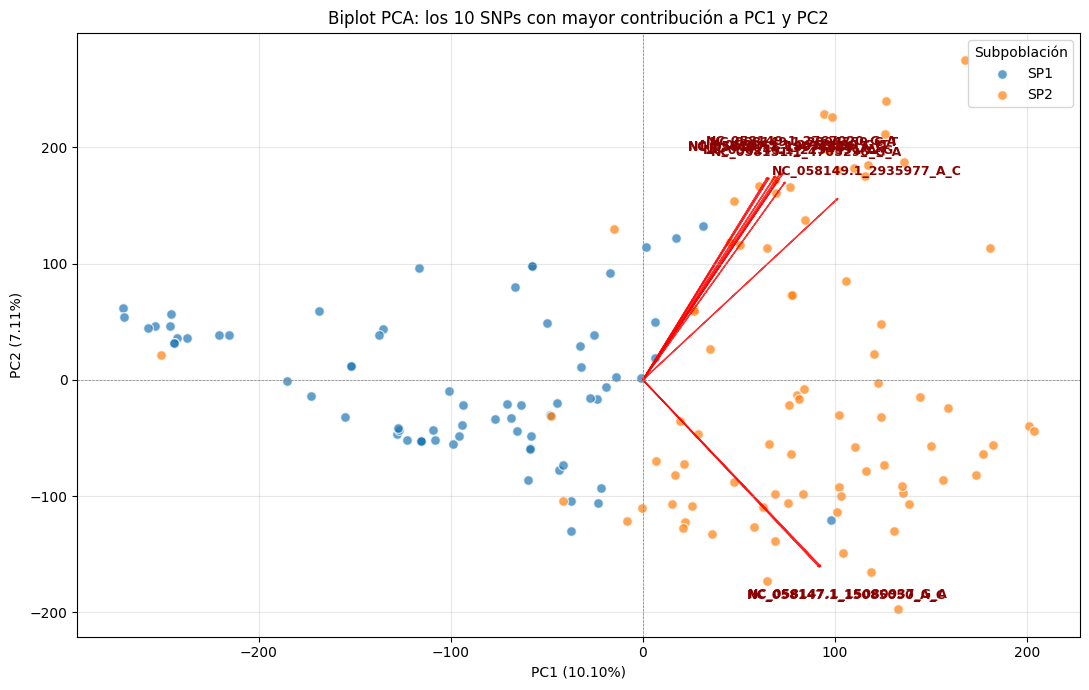

In [8]:
scaler_pca = StandardScaler()
X_para_pca = pd.DataFrame(
    scaler_pca.fit_transform(X_genes_sin_escalar),
    index=X_genes_sin_escalar.index,
    columns=X_genes_sin_escalar.columns.astype(str)
)

etiquetas_alineadas = Y_morfologia['Subpopulation'].values
pca_limpio = PCA()
SNP_PCA_limpio = pca_limpio.fit_transform(X_para_pca)

loadings = pca_limpio.components_.T
magnitudes = np.sqrt(loadings[:, 0]**2 + loadings[:, 1]**2)
top_10_indices = np.argsort(magnitudes)[-10:]
escala = (np.max(np.abs(SNP_PCA_limpio[:, :2])) / np.max(magnitudes)) * 0.7

plt.figure(figsize=(11, 7))
for subpoblacion in np.unique(etiquetas_alineadas):
    indices = (etiquetas_alineadas == subpoblacion)
    plt.scatter(SNP_PCA_limpio[indices, 0], SNP_PCA_limpio[indices, 1], label=subpoblacion, alpha=0.7, s=50, edgecolors='w')

for i in top_10_indices:
    lx, ly = loadings[i, 0], loadings[i, 1]
    plt.arrow(0, 0, lx * escala, ly * escala, color='red', alpha=0.8, head_width=1.0, length_includes_head=True)
    plt.text(lx * escala * 1.15, ly * escala * 1.15, X_para_pca.columns[i], color='darkred', ha='center', va='center', fontsize=9, fontweight='bold')

plt.axhline(0, color='grey', lw=0.5, linestyle='--')
plt.axvline(0, color='grey', lw=0.5, linestyle='--')
plt.xlabel(f'PC1 ({pca_limpio.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca_limpio.explained_variance_ratio_[1]:.2%})')
plt.title('Biplot PCA: los 10 SNPs con mayor contribución a PC1 y PC2')
plt.legend(title='Subpoblación')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Entrenamiento de modelos

In [11]:
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

print("Entrenando Random Forest con el 100% de los datos usando OOB...")
mediana_peso = Y_morfologia['fruitWeight (g)'].median()
y_clasificacion = (Y_morfologia['fruitWeight (g)'] >= mediana_peso).astype(int)


rf_oob = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_oob.fit(X_genes_sin_escalar, y_clasificacion)


y_prob_oob = rf_oob.oob_decision_function_[:, 1]
y_pred_oob = np.argmax(rf_oob.oob_decision_function_, axis=1)

print(f"\n--- RESULTADOS RANDOM FOREST (Evaluación Pura OOB) ---")
print(f"OOB Accuracy Score: {rf_oob.oob_score_:.4f}")
print("\nReporte de Clasificación (calculado sobre predicciones OOB):")
print(classification_report(y_clasificacion, y_pred_oob, target_names=['Bajo Peso (0)', 'Alto Peso (1)']))
print("ROC-AUC OOB:", round(roc_auc_score(y_clasificacion, y_prob_oob), 4))


Entrenando Random Forest con el 100% de los datos usando OOB...

--- RESULTADOS RANDOM FOREST (Evaluación Pura OOB) ---
OOB Accuracy Score: 0.6795

Reporte de Clasificación (calculado sobre predicciones OOB):
               precision    recall  f1-score   support

Bajo Peso (0)       0.67      0.72      0.69        78
Alto Peso (1)       0.69      0.64      0.67        78

     accuracy                           0.68       156
    macro avg       0.68      0.68      0.68       156
 weighted avg       0.68      0.68      0.68       156

ROC-AUC OOB: 0.7561


# Procesamiento Datos obtenidos en Galaxy Europe

In [10]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
ruta_vcf = '/content/drive/MyDrive/Proyecto_Bioinformatica/Tablas_de_Datos/SNP_GALAXY.tabular'

df_crudo = pd.read_csv(ruta_vcf, sep='\t', dtype=str)
filas_originales = len(df_crudo)
print(f"Líneas totales descubiertas por FreeBayes: {filas_originales:,}")
mask_snps_puros = (df_crudo['REF'].str.len() == 1) & (df_crudo['ALT'].str.len() == 1)
df_snps = df_crudo[mask_snps_puros].copy()

filas_limpias = len(df_snps)
print(f"SNPs puros retenidos: {filas_limpias:,}")
print(f"INDELs y variantes complejas descartadas: {filas_originales - filas_limpias:,}")

nombres_columnas = df_snps.columns.tolist()
nuevos_nombres = [col.replace('.GT', '').replace('GEN[', 'Muestra_').replace(']', '') if 'GEN' in col else col for col in nombres_columnas]
df_snps.columns = nuevos_nombres

display(df_snps.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Líneas totales descubiertas por FreeBayes: 11,479,565
SNPs puros retenidos: 7,982,563
INDELs y variantes complejas descartadas: 3,497,002


,CHROM,POS,ID,REF,ALT,FILTER,Muestra_0,Muestra_1,Muestra_2,Muestra_3
0,CM021837.1,33,NaN,G,A,NaN,0/0,0/1,0/0,0/1
2,CM021837.1,51,NaN,T,C,NaN,0/1,1/1,0/1,0/1
3,CM021837.1,57,NaN,C,G,NaN,0/1,0/1,0/1,0/0
4,CM021837.1,61,NaN,T,C,NaN,0/0,0/0,0/1,0/1
5,CM021837.1,72,NaN,C,T,NaN,0/0,0/0,0/0,0/1
